# Propuesta de resolución — Primer parcial de Python
**Matemática para Economistas III — IDEI/UNGS**

Resolución comentada para clase.

# Ejercicio 1 — La escalera del módulo 7

## 1a) En papel

| Paso | Posición |
|---:|---:|
| 0 | 0 |
| 1 | 1 |
| 2 | 2 |
| 3 | 2 |
| 4 | 3 |
| 5 | 4 |
| 6 | 4 |
| 7 | 5 |

La posición 5 aparece por primera vez en el **paso 7**. En el paso 6 llega a 5, pero resbala y termina en 4.

El patrón es claro: cada 3 pasos avanza 2 escalones netos. Por eso se repiten posiciones (2 en los pasos 2 y 3; 4 en los pasos 5 y 6; etc.).

## 1b) Simulación

La lista guarda la posición **después de cada paso**. El contador `n_paso` es el que decide cuándo resbalar.

In [1]:
meta = 20
pos_actual = 0
n_paso = 0
posiciones = []

while pos_actual < meta:
    n_paso += 1
    pos_actual += 1

    if n_paso % 3 == 0 and pos_actual < meta:
        pos_actual -= 1

    posiciones.append(pos_actual)

print("Pasos:", n_paso)
print("Posiciones:", posiciones)

Pasos: 29
Posiciones: [1, 2, 2, 3, 4, 4, 5, 6, 6, 7, 8, 8, 9, 10, 10, 11, 12, 12, 13, 14, 14, 15, 16, 16, 17, 18, 18, 19, 20]


La lista tiene 29 posiciones, una por paso. Si se arranca con `[0]`, quedan 30 valores para 29 pasos: sirve para graficar desde el piso 0, pero la consigna pide la posición después de cada paso. Por eso acá empieza vacía y el gráfico usa `range(1, len(posiciones) + 1)`.

## 1c) Gráfico

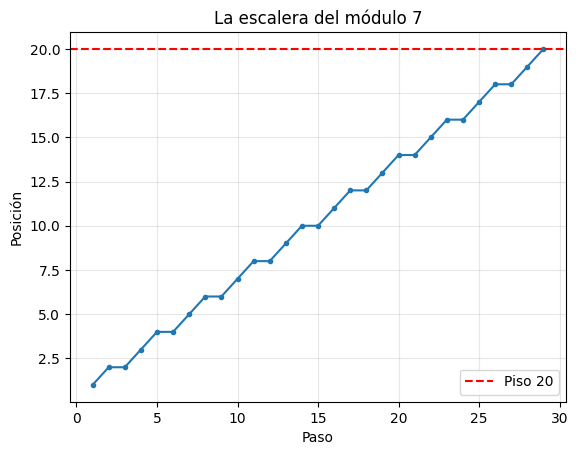

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.plot(range(1, len(posiciones) + 1), posiciones, marker="o", markersize=3)
plt.axhline(20, color="red", linestyle="--", label="Piso 20")

plt.title("La escalera del módulo 7")
plt.xlabel("Paso")
plt.ylabel("Posición")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 1d) Función

La función usa los parámetros y devuelve los pasos y las posiciones. El `raise` evita un bucle infinito si los parámetros no permiten avanzar.

In [3]:
def subir_escalera(meta, sube=1, resbala=1, cada=3):
    """Simula la escalera y devuelve los pasos y las posiciones."""
    if sube * cada <= resbala:
        raise ValueError("Con esos parámetros el estudiante nunca llega a la meta.")

    pos_actual = 0
    n_paso = 0
    posiciones = []

    while pos_actual < meta:
        n_paso += 1
        pos_actual += sube

        if n_paso % cada == 0 and pos_actual < meta:
            pos_actual -= resbala

        posiciones.append(pos_actual)

    return n_paso, posiciones

In [4]:
metas = [20, 100]
j = 0
while j < len(metas):
    meta = metas[j]
    pasos, posiciones = subir_escalera(meta)
    print(f"meta={meta}: {pasos} pasos, {pasos - meta} pasos extra, {pasos / meta:.2f} pasos por piso")
    j += 1

meta=20: 29 pasos, 9 pasos extra, 1.45 pasos por piso
meta=100: 149 pasos, 49 pasos extra, 1.49 pasos por piso


Para 20 hacen falta 29 pasos (9 extra). Para 100, 149 pasos (49 extra). Como cada 3 pasos se suben 2, se necesitan aproximadamente 1,5 pasos por piso: 1 productivo y 0,5 “robado”. La verificación con `raise` evita un loop infinito.

## Errores comunes (Ej1)

**1. Mirar la posición en vez del paso.**

```python
if pos_actual % 3 == 0:   # mal
    pos_actual -= 1
```

En el paso 3 la posición es 2, que no es múltiplo de 3, pero igual debe resbalar porque es el tercer paso. En el paso 4 la posición es 3, que sí es múltiplo, pero no debe resbalar. La condición tiene que mirar el paso (`n_paso % 3`) o un contador de escalones subidos.

**2. Cortar el bucle un paso tarde.**

```python
while pos_actual <= meta:   # mal
```

Con `<=`, cuando ya está en 20 el bucle sigue y agrega un paso de más. Va `< meta`.

**3. Dejar la meta fija en 20.**

```python
def subir_escalera():
    ...
    while pos_actual < 20:   # mal
```

La función tiene que usar el parámetro `meta`; si no, no sirve para 100.

# Ejercicio 2 — El bar de la UNGS

La máquina revisa en este orden: código, stock y dinero. Si falla uno, rechaza y guarda el motivo. Al final arma el resumen.

In [5]:
catalogo = {
    "A1": ("Alfajor de maicena", 1200),
    "B2": ("Cafe con leche", 1500),
    "C3": ("Submarino", 2000),
    "D4": ("Medialuna", 900),
    "E5": ("Galletitas marineras", 800),
}

pedidos = [
    ("A1", 2000), ("D4", 500), ("Z9", 5000), ("C3", 2000),
    ("C3", 2500), ("B2", 1500), ("C3", 100), ("A1", 1200),
    ("C3", 2000), ("E5", 1000),
]


def claves_con_maximo(conteo):
    """Devuelve las claves con el valor máximo (contempla empates)."""
    claves = list(conteo.keys())
    maximo = 0
    ganadores = []
    j = 0

    while j < len(claves):
        valor = conteo[claves[j]]
        if valor > maximo:
            maximo = valor
            ganadores = [claves[j]]
        elif valor == maximo and valor > 0:
            ganadores.append(claves[j])
        j += 1

    return ganadores


def atender_maquina(pedidos, catalogo, stock=4):
    """Simula un día de la máquina y devuelve el resumen."""
    stock_actual = {}
    unidades_vendidas = {}
    claves = list(catalogo.keys())

    k = 0
    while k < len(claves):
        stock_actual[claves[k]] = stock
        unidades_vendidas[claves[k]] = 0
        k += 1

    bitacora = []
    recaudacion = 0

    j = 0
    while j < len(pedidos):
        codigo, dinero = pedidos[j]

        if codigo not in catalogo:
            bitacora.append((codigo, "rechazado", "codigo inexistente"))
        elif stock_actual[codigo] == 0:
            bitacora.append((codigo, "rechazado", "stock agotado"))
        else:
            nombre, precio = catalogo[codigo]
            if dinero < precio:
                bitacora.append((codigo, "rechazado", "dinero insuficiente"))
            else:
                vuelto = dinero - precio
                stock_actual[codigo] -= 1
                unidades_vendidas[codigo] += 1
                recaudacion += precio
                bitacora.append((codigo, "vendido", f"vuelto: ${vuelto}"))
        j += 1

    motivos = {}
    j = 0
    while j < len(bitacora):
        codigo, estado, detalle = bitacora[j]
        if estado == "rechazado":
            if detalle in motivos:
                motivos[detalle] += 1
            else:
                motivos[detalle] = 1
        j += 1

    return {
        "recaudacion": recaudacion,
        "unidades_vendidas": unidades_vendidas,
        "mas_vendidos": claves_con_maximo(unidades_vendidas),
        "motivos_rechazo": motivos,
        "motivo_mas_frecuente": claves_con_maximo(motivos),
        "stock_final": stock_actual,
        "bitacora": bitacora,
    }

In [6]:
stocks = [4, 2]
j = 0
while j < len(stocks):
    resumen = atender_maquina(pedidos, catalogo, stock=stocks[j])
    print(f"===== stock={stocks[j]} =====")
    print("Recaudación:", resumen["recaudacion"])
    print("Unidades vendidas:", resumen["unidades_vendidas"])
    print("Más vendidos:", resumen["mas_vendidos"])
    print("Motivos:", resumen["motivos_rechazo"])
    print("Motivo más frecuente:", resumen["motivo_mas_frecuente"])
    print("Stock final:", resumen["stock_final"])
    print()
    j += 1

===== stock=4 =====
Recaudación: 10700
Unidades vendidas: {'A1': 2, 'B2': 1, 'C3': 3, 'D4': 0, 'E5': 1}
Más vendidos: ['C3']
Motivos: {'dinero insuficiente': 2, 'codigo inexistente': 1}
Motivo más frecuente: ['dinero insuficiente']
Stock final: {'A1': 2, 'B2': 3, 'C3': 1, 'D4': 4, 'E5': 3}

===== stock=2 =====
Recaudación: 8700
Unidades vendidas: {'A1': 2, 'B2': 1, 'C3': 2, 'D4': 0, 'E5': 1}
Más vendidos: ['A1', 'C3']
Motivos: {'dinero insuficiente': 1, 'codigo inexistente': 1, 'stock agotado': 2}
Motivo más frecuente: ['stock agotado']
Stock final: {'A1': 0, 'B2': 1, 'C3': 0, 'D4': 2, 'E5': 1}



Con `stock=4` se recaudan $10.700 y el más vendido es C3, con 3 unidades. Con `stock=2` se recaudan $8.700; C3 y A1 empatan con 2 unidades y los rechazos por stock suben a 2.

El pedido `("C3", 100)` se rechaza por stock, no por dinero, porque el stock se revisa antes. El diccionario del catálogo permite buscar por código; la lista de tuplas conserva el orden de los pedidos y de la bitácora.

## Errores comunes (Ej2)

**1. Usar un stock escalar.**

```python
stock = 4
stock[codigo] -= 1   # mal: stock no es un diccionario
```

Hay que llevar las unidades de cada producto por separado.

**2. Revisar el dinero antes que el stock.**

```python
if dinero < precio:
    ...
elif stock[codigo] == 0:
    ...
```

Con `stock=2`, C3 con $100 queda como “dinero insuficiente”, cuando en realidad ya no hay stock. El orden correcto es código, stock y después dinero.

**3. Sumar el dinero ingresado en vez del precio.**

```python
recaudacion += dinero   # mal: incluye el vuelto
```

La recaudación es la suma de los precios de las ventas, no de los billetes que entraron.

**4. No devolver el resumen o no reiniciar el stock.**

```python
def atender_maquina(...):
    print(...)   # mal: no devuelve nada
```

La función tiene que devolver el diccionario y armar el stock de nuevo en cada llamada. Si no, la segunda corrida arranca con menos unidades.

# Ejercicio 3 — La tasa oculta del Chiqui

El préstamo es $1.000.000 y se devuelve en 24 cuotas de $55.000. La tasa implícita es la que iguala el valor presente de las cuotas con el préstamo.

> Si `numpy_financial` no está instalado, ejecutar una vez `!pip install numpy-financial`.

In [7]:
import numpy_financial as npf

prestamo = 1_000_000
cuota = 55_000
n = 24

i_mensual = npf.rate(n, -cuota, prestamo, 0)
print("Tasa mensual:", i_mensual * 100, "%")

vp = npf.pv(i_mensual, n, -cuota, 0)
print("Valor presente:", vp)

tna = 12 * i_mensual
tea = (1 + i_mensual) ** 12 - 1

print("TNA:", tna * 100, "%")
print("TEA:", tea * 100, "%")

Tasa mensual: 2.351557925642644 %
Valor presente: 999999.9999543328
TNA: 28.218695107711728 %
TEA: 32.170182904733345 %


La tasa mensual es 2,3516%. El valor presente da $1.000.000 (con diferencias de redondeo). La TNA es 28,22% y la TEA es 32,17%.

La TEA es mayor porque capitaliza mensualmente. Al Chiqui le diría que no es “sin interés”: el costo es 2,35% mensual. Conviene aceptar solo si no hay una alternativa más barata.

## Errores comunes (Ej3)

**1. Equivocar los signos.**

```python
i = npf.rate(24, 55000, -1000000, 0)   # mal
```

Las cuotas van negativas y el préstamo positivo. Si se invierten, la tasa no tiene sentido.

**2. Confundir un cociente de flujos con una tasa.**

```python
tasa = 24 * 55000 / 1000000   # mal
```

Eso no es una tasa por período; solo compara el total devuelto con el préstamo.

**3. Calcular la TEA como si fuera la TNA.**

```python
tea = 12 * i_mensual   # mal: eso es la TNA
```

La TEA es `(1 + i_mensual) ** 12 - 1`, porque capitaliza.